In [2]:

%pip install soundfile


   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ---------------------------------------- 1.0/1.0 MB 6.1 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Audio loaded successfully!
Sample rate: 4000 Hz
Duration: 13.39 seconds
Audio shape: (53568,)


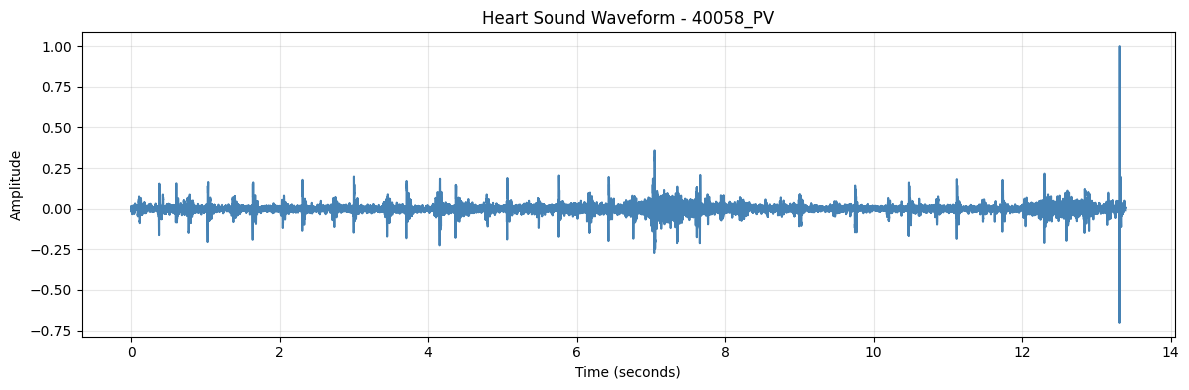

In [3]:

# Load and visualize a heart sound recording

import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
from pathlib import Path

# Path to the heart sound recording
audio_path = Path("../data/raw/40058_PV.wav")

# Load the audio file
audio, sample_rate = sf.read(audio_path)

# Display recording information
duration = len(audio) / sample_rate

print("Audio loaded successfully!")
print("Sample rate:", sample_rate, "Hz")
print("Duration:", round(duration, 2), "seconds")
print("Audio shape:", audio.shape)

# Create time axis
time = np.arange(len(audio)) / sample_rate

# Plot the waveform
plt.figure(figsize=(12, 4))
plt.plot(time, audio, color="steelblue")

plt.title("Heart Sound Waveform - 40058_PV")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [4]:

# Listen to the heart sound recording

from IPython.display import Audio, display

print("Playing heart sound recording: 40058_PV.wav")

# Create an audio player inside the notebook
display(Audio(audio, rate=sample_rate))


Playing heart sound recording: 40058_PV.wav


Create a spectrogram

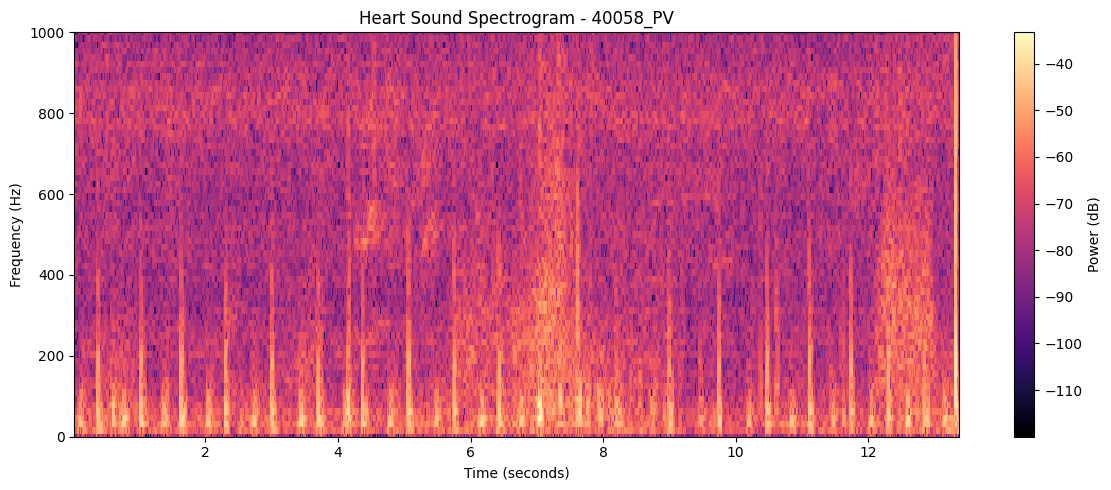

In [5]:

# Create a spectrogram of the heart sound recording

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import spectrogram

# Convert to mono if the audio has multiple channels
audio_mono = audio.mean(axis=1) if audio.ndim > 1 else audio

# Calculate the spectrogram
frequencies, times, power = spectrogram(
    audio_mono,
    fs=sample_rate,
    nperseg=256,
    noverlap=192
)

# Convert power to decibels
power_db = 10 * np.log10(power + 1e-12)

# Plot the spectrogram
plt.figure(figsize=(12, 5))

plt.pcolormesh(
    times,
    frequencies,
    power_db,
    shading="auto",
    cmap="magma"
)

plt.colorbar(label="Power (dB)")
plt.title("Heart Sound Spectrogram - 40058_PV")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")

# Focus on lower frequencies
plt.ylim(0, 1000)

plt.tight_layout()
plt.show()


Extract MFCC features

In [6]:

%pip install librosa


   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   ------------------------------------- -- 2.6/2.8 MB 15.1 MB/s eta 0:00:01
   ---------------------------------------- 2.8/2.8 MB 14.9 MB/s  0:00:00
   ---------------------------------------- 0.0/41.9 MB ? eta -:--:--
   --- ------------------------------------ 3.9/41.9 MB 18.1 MB/s eta 0:00:03
   -------- ------------------------------- 8.9/41.9 MB 20.5 MB/s eta 0:00:02
   -------------- ------------------------- 14.9/41.9 MB 23.5 MB/s eta 0:00:02
   ------------------- -------------------- 20.4/41.9 MB 23.9 MB/s eta 0:00:01
   ------------------------ --------------- 25.4/41.9 MB 24.0 MB/s eta 0:00:01
   ------------------------------- -------- 32.8/41.9 MB 25.7 MB/s eta 0:00:01
   ------------------------------------- -- 39.6/41.9 MB 26.5 MB/s eta 0:00:01
   ---------------------------------------  41.7/41.9 MB 25.5 MB/s eta 0:00:01
   ---------------------------------------- 41.9/41.9 MB 23.8 MB/s  0:00:01

   


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


MFCC shape: (13, 210)


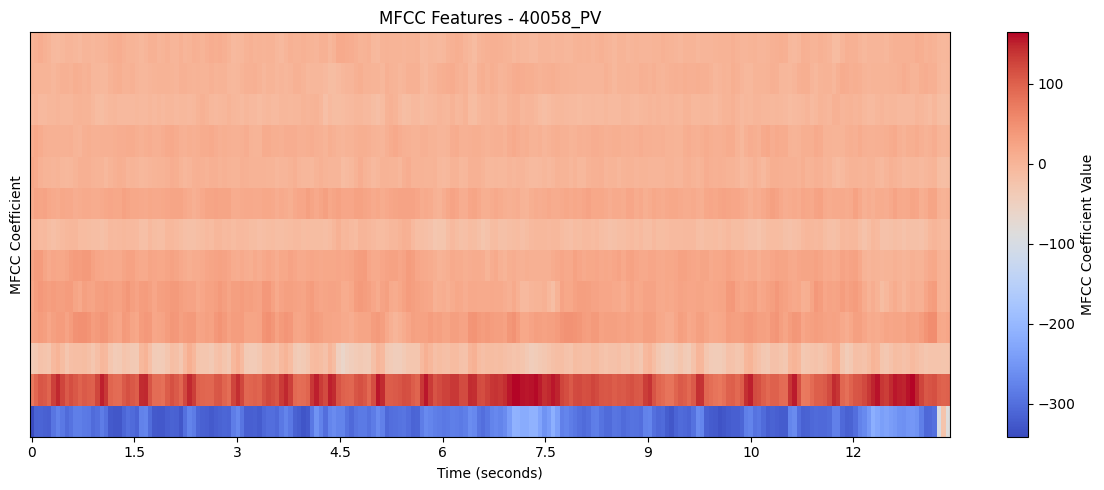

In [7]:

# Extract MFCC features from the heart sound recording

import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt

# Extract 13 MFCC coefficients
mfccs = librosa.feature.mfcc(
    y=audio_mono.astype(float),
    sr=sample_rate,
    n_mfcc=13,
    n_fft=1024,
    hop_length=256
)

print("MFCC shape:", mfccs.shape)

# Visualize MFCC features
plt.figure(figsize=(12, 5))

librosa.display.specshow(
    mfccs,
    sr=sample_rate,
    hop_length=256,
    x_axis="time",
    cmap="coolwarm"
)

plt.colorbar(label="MFCC Coefficient Value")
plt.title("MFCC Features - 40058_PV")
plt.xlabel("Time (seconds)")
plt.ylabel("MFCC Coefficient")
plt.tight_layout()
plt.show()


Save our audio visualizations

In [8]:

# Save audio exploration visualizations

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

# Location for saved figures
figures_path = Path("../reports/figures")
figures_path.mkdir(parents=True, exist_ok=True)

# 1. Save waveform
plt.figure(figsize=(12, 4))
plt.plot(time, audio, color="steelblue")
plt.title("Heart Sound Waveform - 40058_PV")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.savefig(figures_path / "heart_sound_waveform.png", dpi=300)
plt.close()

# 2. Save spectrogram
plt.figure(figsize=(12, 5))
plt.pcolormesh(
    times, frequencies, power_db,
    shading="auto", cmap="magma"
)
plt.colorbar(label="Power (dB)")
plt.title("Heart Sound Spectrogram - 40058_PV")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.ylim(0, 1000)
plt.tight_layout()
plt.savefig(figures_path / "heart_sound_spectrogram.png", dpi=300)
plt.close()

# 3. Save MFCC heatmap
plt.figure(figsize=(12, 5))
librosa.display.specshow(
    mfccs,
    sr=sample_rate,
    hop_length=256,
    x_axis="time",
    cmap="coolwarm"
)
plt.colorbar(label="MFCC Coefficient Value")
plt.title("MFCC Features - 40058_PV")
plt.xlabel("Time (seconds)")
plt.ylabel("MFCC Coefficient")
plt.tight_layout()
plt.savefig(figures_path / "heart_sound_mfcc.png", dpi=300)
plt.close()

print("All three audio visualizations saved successfully!")


All three audio visualizations saved successfully!




## Audio Exploration Summary

This analysis examined a heart sound recording from the
CirCor DigiScope Phonocardiogram Dataset.

### Recording Information
- File: 40058_PV.wav
- Sampling rate: 4000 Hz
- Duration: 13.39 seconds
- Total samples: 53,568

### Key Findings

1. **Waveform Analysis:** The waveform shows variations in
   sound amplitude throughout the recording. Several
   peaks represent short bursts of acoustic activity.

2. **Spectrogram Analysis:** The spectrogram illustrates
   how the frequency content changes over time.
   Stronger energy is visible at lower frequencies,
   along with several short-duration frequency bursts.

3. **MFCC Feature Extraction:** We extracted 13 MFCC
   coefficients across 210 time frames. These features
   summarize aspects of the recording's spectral
   characteristics and may be useful for classification.

### Implications for Machine Learning

Audio recordings must be preprocessed consistently
before model training. Potential preprocessing steps
include normalization, filtering, and segmentation.

MFCC features can be used with traditional machine
learning models, while spectrograms can be used
as inputs for convolutional neural networks.

### Conclusion

The exploratory audio analysis successfully demonstrated
loading, visualizing, and extracting features from one
heart sound recording. Further work requires additional
labeled recordings to train and evaluate classification
models.


In [12]:

# Check basic audio signal quality

import numpy as np

# Calculate audio statistics
peak_amplitude = np.max(np.abs(audio_mono))
rms_amplitude = np.sqrt(np.mean(audio_mono ** 2))
mean_amplitude = np.mean(audio_mono)

print("Audio Signal Statistics")
print("-----------------------")
print(f"Peak amplitude: {peak_amplitude:.4f}")
print(f"RMS amplitude: {rms_amplitude:.4f}")
print(f"Mean amplitude: {mean_amplitude:.4f}")
print(f"Minimum value: {np.min(audio_mono):.4f}")
print(f"Maximum value: {np.max(audio_mono):.4f}")


Audio Signal Statistics
-----------------------
Peak amplitude: 1.0000
RMS amplitude: 0.0317
Mean amplitude: -0.0003
Minimum value: -0.7026
Maximum value: 1.0000


Audio preprocessing successful!
Sample rate: 4000
Processed audio shape: (53568,)


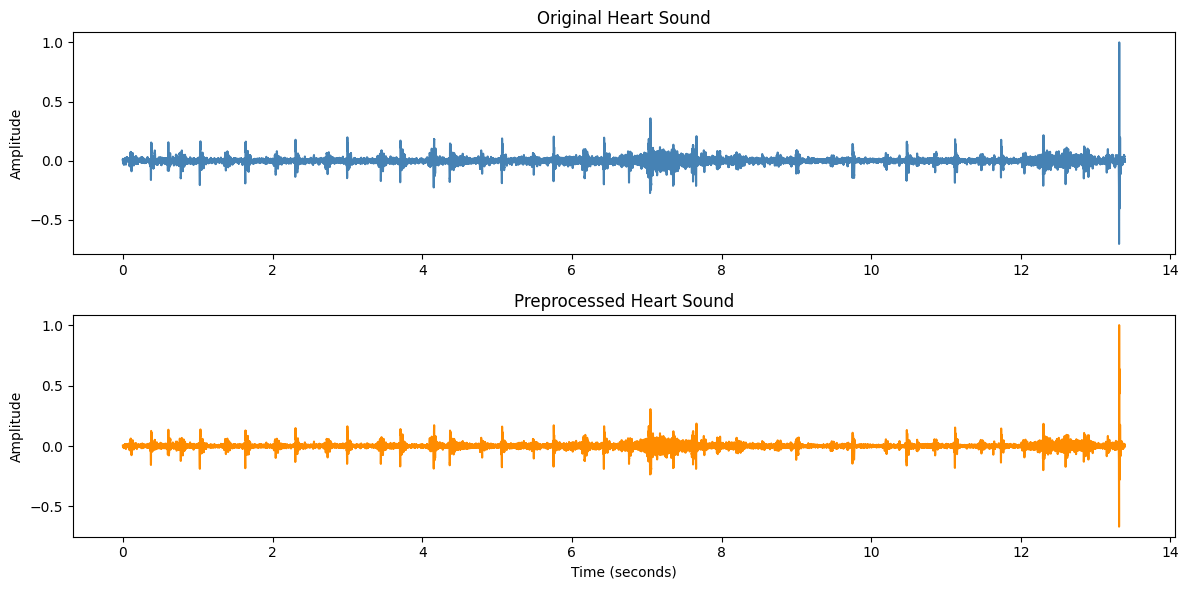

In [13]:

# Test our audio preprocessing function

import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Allow notebook to import functions from the project
sys.path.insert(0, str(Path("..").resolve()))

from src.preprocessing.audio_preprocessing import preprocess_audio

# Load and preprocess our heart sound recording
processed_audio, processed_sr = preprocess_audio(
    "../data/raw/40058_PV.wav"
)

print("Audio preprocessing successful!")
print("Sample rate:", processed_sr)
print("Processed audio shape:", processed_audio.shape)

# Compare original and processed audio
processed_time = np.arange(len(processed_audio)) / processed_sr

plt.figure(figsize=(12, 6))

plt.subplot(2, 1, 1)
plt.plot(time, audio, color="steelblue")
plt.title("Original Heart Sound")
plt.ylabel("Amplitude")

plt.subplot(2, 1, 2)
plt.plot(processed_time, processed_audio, color="darkorange")
plt.title("Preprocessed Heart Sound")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()


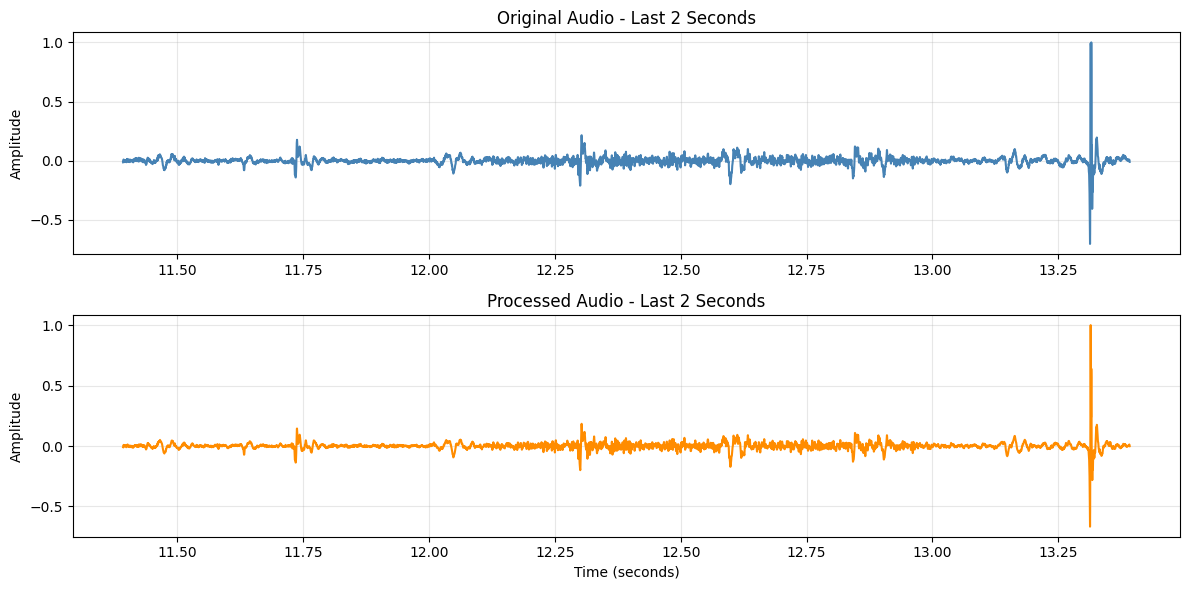

Largest peak occurs at: 13.32 seconds


In [14]:

# Investigate the spike near the end of the recording

import matplotlib.pyplot as plt
import numpy as np

# Select the last 2 seconds
start_time = max(0, duration - 2)

original_mask = time >= start_time
processed_mask = processed_time >= start_time

plt.figure(figsize=(12, 6))

# Original audio
plt.subplot(2, 1, 1)
plt.plot(time[original_mask], audio[original_mask],
         color="steelblue")
plt.title("Original Audio - Last 2 Seconds")
plt.ylabel("Amplitude")
plt.grid(alpha=0.3)

# Processed audio
plt.subplot(2, 1, 2)
plt.plot(
    processed_time[processed_mask],
    processed_audio[processed_mask],
    color="darkorange"
)
plt.title("Processed Audio - Last 2 Seconds")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Locate the largest peak
peak_index = np.argmax(np.abs(audio_mono))
peak_time = peak_index / sample_rate

print(f"Largest peak occurs at: {peak_time:.2f} seconds")


Test trimming the recording

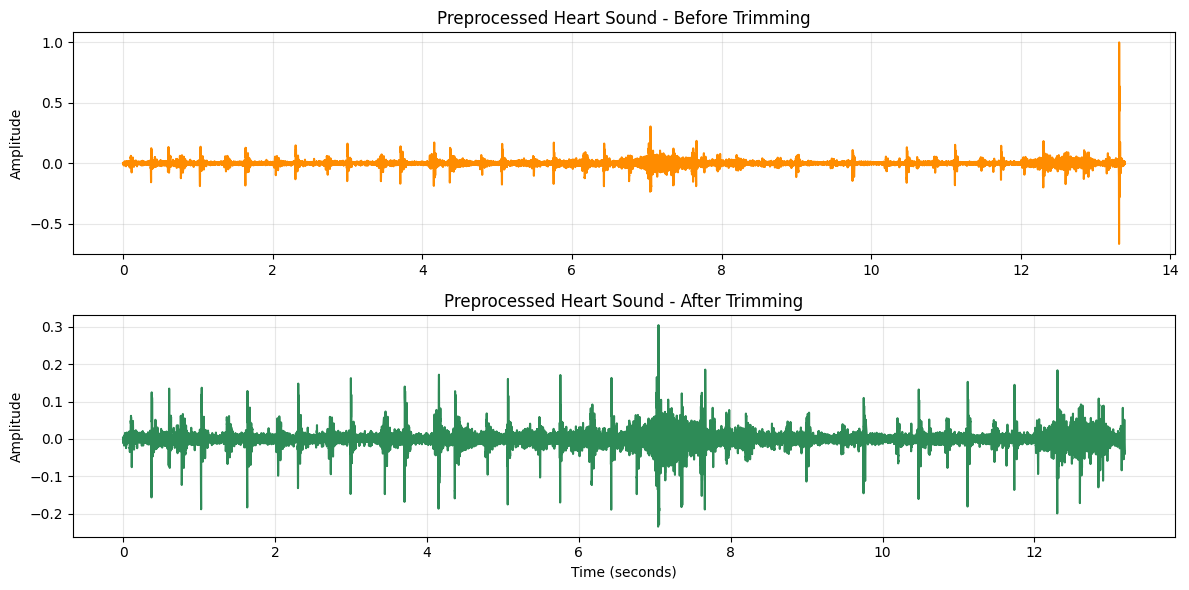

Original duration: 13.39 seconds
Trimmed duration: 13.19 seconds
Original peak: 1.0
Trimmed peak: 0.3048


In [15]:

# Experiment: trim the final 0.2 seconds

import numpy as np
import matplotlib.pyplot as plt

# Remove the final 0.2 seconds from processed audio
trim_seconds = 0.2
trim_samples = int(trim_seconds * processed_sr)

trimmed_audio = processed_audio[:-trim_samples]

# Create time axis for trimmed audio
trimmed_time = np.arange(len(trimmed_audio)) / processed_sr

# Compare the signals
plt.figure(figsize=(12, 6))

plt.subplot(2, 1, 1)
plt.plot(processed_time, processed_audio, color="darkorange")
plt.title("Preprocessed Heart Sound - Before Trimming")
plt.ylabel("Amplitude")
plt.grid(alpha=0.3)

plt.subplot(2, 1, 2)
plt.plot(trimmed_time, trimmed_audio, color="seagreen")
plt.title("Preprocessed Heart Sound - After Trimming")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Original duration:",
      round(len(processed_audio) / processed_sr, 2), "seconds")

print("Trimmed duration:",
      round(len(trimmed_audio) / processed_sr, 2), "seconds")

print("Original peak:",
      round(np.max(np.abs(processed_audio)), 4))

print("Trimmed peak:",
      round(np.max(np.abs(trimmed_audio)), 4))


Compare the Audio Statistics

In [16]:

# Compare audio statistics before and after trimming

import numpy as np
import pandas as pd

def get_audio_stats(signal):
    return {
        "Duration (s)": len(signal) / processed_sr,
        "Peak Amplitude": np.max(np.abs(signal)),
        "RMS Amplitude": np.sqrt(np.mean(signal ** 2)),
        "Mean Amplitude": np.mean(signal)
    }

# Compare both versions
comparison = pd.DataFrame({
    "Before Trimming": get_audio_stats(processed_audio),
    "After Trimming": get_audio_stats(trimmed_audio)
})

# Display comparison table
display(comparison.round(4))


,Before Trimming,After Trimming
Duration (s),13.3920,13.1920
Peak Amplitude,1.0000,0.3048
RMS Amplitude,0.0271,0.0251
Mean Amplitude,-0.0000,-0.0000


Improve Normalization method

99th percentile amplitude: 0.1104
New peak amplitude: 9.0597


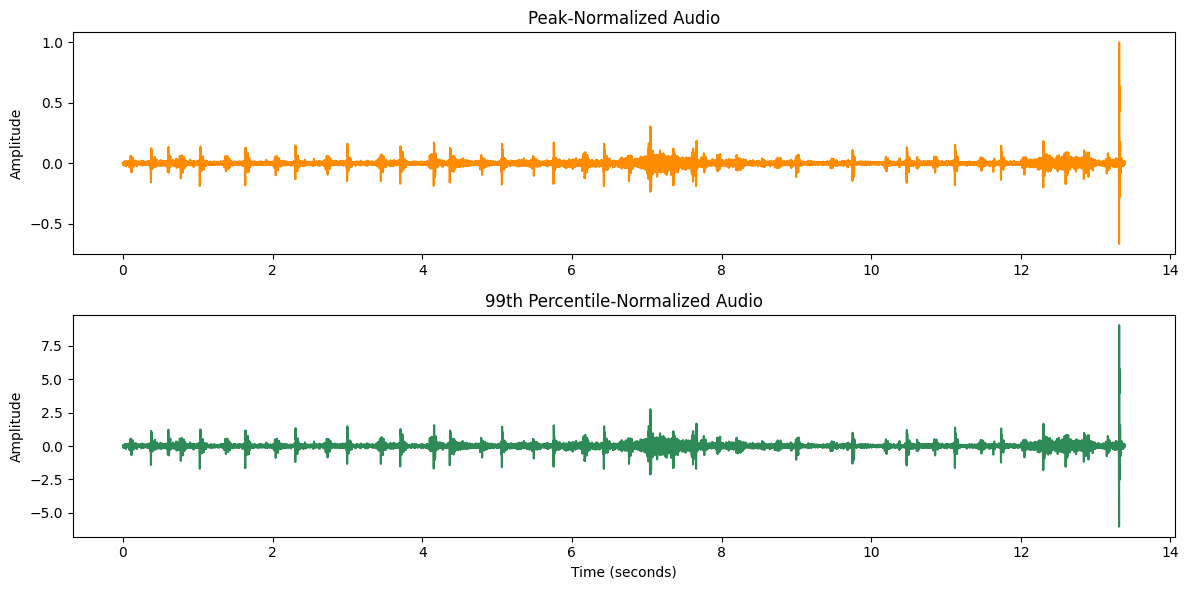

In [17]:

# Experiment with robust amplitude normalization

import numpy as np
import matplotlib.pyplot as plt

# Use the 99th percentile of absolute amplitude
scale = np.percentile(np.abs(processed_audio), 99)

# Prevent division by zero
if scale > 0:
    robust_audio = processed_audio / scale
else:
    robust_audio = processed_audio.copy()

# Display statistics
print("99th percentile amplitude:", round(scale, 4))
print("New peak amplitude:", round(np.max(np.abs(robust_audio)), 4))

# Compare original processed audio and robust-normalized audio
plt.figure(figsize=(12, 6))

plt.subplot(2, 1, 1)
plt.plot(processed_time, processed_audio, color="darkorange")
plt.title("Peak-Normalized Audio")
plt.ylabel("Amplitude")

plt.subplot(2, 1, 2)
plt.plot(processed_time, robust_audio, color="seagreen")
plt.title("99th Percentile-Normalized Audio")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()


Test normalization with a shared scale

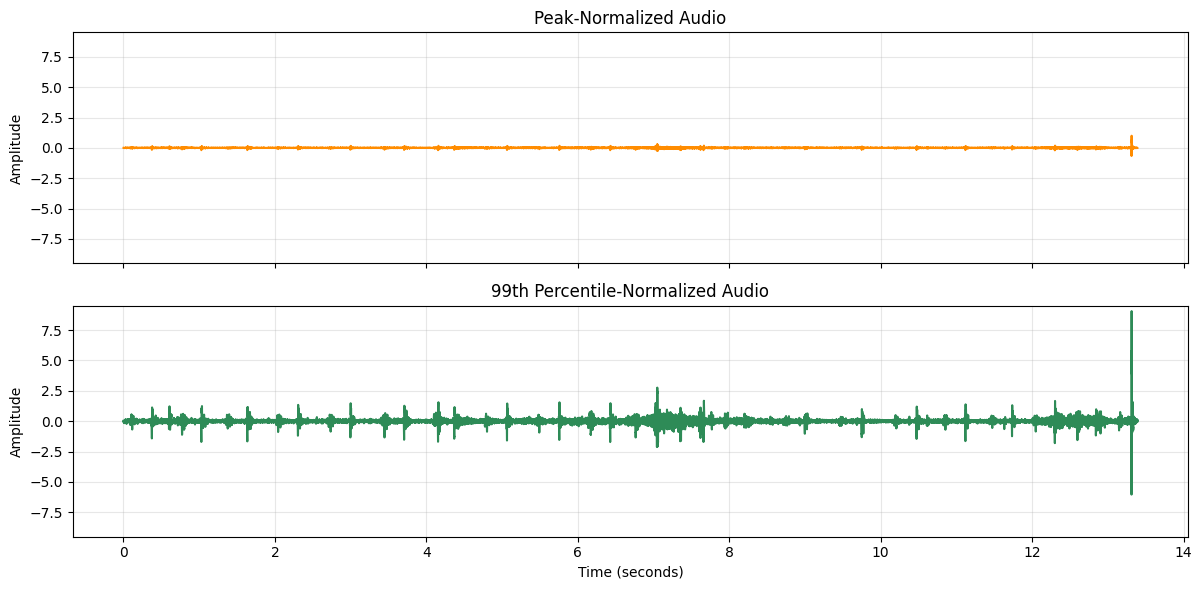

In [18]:

# Compare normalization methods using the same amplitude scale

import matplotlib.pyplot as plt
import numpy as np

# Use the same vertical limits for both plots
limit = max(
    np.max(np.abs(processed_audio)),
    np.max(np.abs(robust_audio))
) * 1.05

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

# Peak-normalized audio
axes[0].plot(processed_time, processed_audio, color="darkorange")
axes[0].set_title("Peak-Normalized Audio")
axes[0].set_ylabel("Amplitude")
axes[0].set_ylim(-limit, limit)
axes[0].grid(alpha=0.3)

# Percentile-normalized audio
axes[1].plot(processed_time, robust_audio, color="seagreen")
axes[1].set_title("99th Percentile-Normalized Audio")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Amplitude")
axes[1].set_ylim(-limit, limit)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [19]:

# Test our MFCC feature extraction function

from src.features.extract_features import extract_mfcc_features

# Extract features from our preprocessed recording
features = extract_mfcc_features(
    processed_audio,
    processed_sr
)

# Display results
print("Feature extraction successful!")
print("Number of features:", len(features))
print("Feature vector shape:", features.shape)
print("\nExtracted MFCC features:")
print(features)


Feature extraction successful!
Number of features: 26
Feature vector shape: (26,)

Extracted MFCC features:
[-435.27524    235.94882    -16.338501   -29.302471    45.786255
   20.183846   -15.603261     5.376864    12.678208    -3.486367
   -3.232659     1.5241339   -1.0948278   30.276236    25.411144
   14.261303     9.021192     8.055152     8.870418     5.866676
    4.3961277    5.804734     3.9895754    4.198943     4.312663
    4.0058513]


In [20]:

# Test complete preprocessing and feature extraction pipeline

from pathlib import Path
from src.preprocessing.audio_preprocessing import preprocess_audio
from src.features.extract_features import extract_mfcc_features
import numpy as np

# Path to our sample recording
file_path = Path("../data/raw/40058_PV.wav")

# Step 1: Preprocess audio
clean_audio, sr = preprocess_audio(file_path)

# Step 2: Extract MFCC features
feature_vector = extract_mfcc_features(clean_audio, sr)

# Step 3: Check the results
print("Audio pipeline completed successfully!")
print("File:", file_path.name)
print("Sample rate:", sr)
print("Number of features:", len(feature_vector))
print("Feature vector shape:", feature_vector.shape)
print("All values finite:", np.isfinite(feature_vector).all())


Audio pipeline completed successfully!
File: 40058_PV.wav
Sample rate: 4000
Number of features: 26
Feature vector shape: (26,)
All values finite: True


In [21]:

# Find the patient information for our audio recording

import pandas as pd
from pathlib import Path

# Load the patient metadata
metadata = pd.read_csv("../data/raw/training_data.csv")

# Extract patient ID from the audio filename
audio_filename = Path("../data/raw/40058_PV.wav").name
patient_id = int(audio_filename.split("_")[0])

# Find the matching patient
patient_info = metadata[
    metadata["Patient ID"] == patient_id
]

print("Patient ID:", patient_id)
print("Matching records:", len(patient_info))

# Display selected patient information
display(
    patient_info[
        ["Patient ID", "Age", "Sex", "Murmur", "Murmur locations"]
    ]
)


Patient ID: 40058
Matching records: 1


,Patient ID,Age,Sex,Murmur,Murmur locations
17,40058,Child,Female,Absent,NaN


In [22]:

# Create a labeled feature record

import pandas as pd
import numpy as np

# Generate names for the 26 MFCC features
feature_names = (
    [f"mfcc_mean_{i}" for i in range(1, 14)] +
    [f"mfcc_std_{i}" for i in range(1, 14)]
)

# Create a DataFrame from our extracted features
labeled_features = pd.DataFrame(
    [feature_vector],
    columns=feature_names
)

# Add patient information and label
labeled_features.insert(0, "Patient ID", patient_id)
labeled_features["Murmur"] = patient_info["Murmur"].iloc[0]

print("Labeled feature dataset created!")
print("Dataset shape:", labeled_features.shape)

# Display the first few columns
display(labeled_features.iloc[:, :8])


Labeled feature dataset created!
Dataset shape: (1, 28)


,Patient ID,mfcc_mean_1,mfcc_mean_2,mfcc_mean_3,mfcc_mean_4,mfcc_mean_5,mfcc_mean_6,mfcc_mean_7
0,40058,-435.275238,235.948822,-16.338501,-29.302471,45.786255,20.183846,-15.603261


In [23]:

# Build a labeled feature dataset from audio recordings

from pathlib import Path
import pandas as pd
import numpy as np

def build_feature_dataset(audio_folder, metadata):
    rows = []

    # Find WAV files in the folder and any subfolders
    audio_files = sorted(Path(audio_folder).rglob("*.wav"))

    # Look up patient labels by ID
    labels = metadata.copy()
    labels["Patient ID"] = labels["Patient ID"].astype(str)
    labels = labels.set_index("Patient ID")

    for file in audio_files:
        patient_id = file.stem.split("_")[0]

        # Skip files without a matching patient
        if patient_id not in labels.index:
            continue

        murmur = labels.loc[patient_id, "Murmur"]

        # Keep only known labels for binary classification
        if murmur not in ["Present", "Absent"]:
            continue

        try:
            # Preprocess recording
            clean_audio, sr = preprocess_audio(file)

            # Extract 26 MFCC features
            vector = extract_mfcc_features(clean_audio, sr)

            if not np.isfinite(vector).all():
                continue

            # Store the result
            row = {"Patient ID": patient_id,
                   "Recording": file.name,
                   "Murmur": murmur}

            row.update(dict(zip(feature_names, vector)))
            rows.append(row)

        except Exception as e:
            print(f"Skipped {file.name}: {e}")

    return pd.DataFrame(rows)


# Build dataset using our available audio files
feature_dataset = build_feature_dataset(
    "../data/raw",
    metadata
)

print("Total labeled recordings:", len(feature_dataset))
print("Dataset shape:", feature_dataset.shape)
display(feature_dataset.head())


Total labeled recordings: 1
Dataset shape: (1, 29)


,Patient ID,Recording,Murmur,mfcc_mean_1,mfcc_mean_2,mfcc_mean_3,mfcc_mean_4,mfcc_mean_5,mfcc_mean_6,mfcc_mean_7,...,mfcc_std_4,mfcc_std_5,mfcc_std_6,mfcc_std_7,mfcc_std_8,mfcc_std_9,mfcc_std_10,mfcc_std_11,mfcc_std_12,mfcc_std_13
0,40058,40058_PV.wav,Absent,-435.275238,235.948822,-16.338501,-29.302471,45.786255,20.183846,-15.603261,...,9.021192,8.055152,8.870418,5.866676,4.396128,5.804734,3.989575,4.198943,4.312663,4.005851


In [24]:

# Save extracted features to a CSV file

from pathlib import Path

# Create output folder
output_folder = Path("../data/processed")
output_folder.mkdir(parents=True, exist_ok=True)

# Save labeled features
output_file = output_folder / "heart_sound_features.csv"

feature_dataset.to_csv(output_file, index=False)

print("Feature dataset saved successfully!")
print("File:", output_file)
print("Shape:", feature_dataset.shape)


Feature dataset saved successfully!
File: ..\data\processed\heart_sound_features.csv
Shape: (1, 29)
